# 등록 그림 크기·비율 기준: 상세 페이지 칸별 확대 배율과 채움 (11/04)

앱에서 올리는 그림(게임 등록의 레퍼런스 아트, A 스크린샷, F·D 굿즈 사진)이 너무 작거나 비율이 극단이면 상세 페이지에서 흐리게 늘어나거나 칸 안에 좁은 띠로 들어간다(26 시험 22·23). 올릴 때 막고 필요한 크기·비율을 안내하기로 했고(11/04 결정), 그 기준을 정하려고 크기·비율을 바꿔 가며 상세 페이지를 그려 본다.

- 그리는 코드: 앱 상세 페이지 코드 `src/app/core/page_html.py`를 그대로 읽어 쓴다(21과 같은 코드, 26 2번 방식).
- 시험 그림: 원본을 가운데에서 비율대로 자른 뒤 긴 변을 크기에 맞춰 줄인다. 원본 긴 변이 680px 이상이라 모든 시험 그림은 줄이기만 한다.
  - 크기(긴 변): 64, 128, 256, 512px
  - 비율(가로:세로): 3:1, 2:1, 16:9, 4:3, 1:1, 3:4, 2:3, 1:2, 1:3. 사용자가 정한 1:1~1:3과 3:1에, 게임 스크린샷에 흔한 16:9와 그 사이 가로 비율(2:1, 4:3)과 2:3을 더했다.
- 칸과 원본 (36가지 = 비율 9 × 크기 4, 한 페이지에 네 칸을 함께 바꿈)

  | 칸 | 올리는 그림 | 원본 | 맞춤 방식 |
  |---|---|---|---|
  | 게임 화면 큰 칸 (`shot`) | A 스크린샷 | 냥기사 스크린샷 1024×1024 | 칸 폭에 맞추고 높이 최대 900px, 넘치면 줄임(contain) |
  | 레퍼런스 칸 (`refs`) | 게임 등록 레퍼런스 아트 | 냥기사 레퍼런스(고양이 기사) 1024×1024 | 정사각 칸을 채우고 넘치는 부분을 자름(cover) |
  | 굿즈 디자인 칸 (`mockup`) | F 굿즈 사진 (③ 목업) | 21 ③ 목업 결과(F1cloth 티셔츠) 1024×680 | 폭 620px, 높이 최대 820px, contain |
  | 연출 사진 칸 (`d`) | D 굿즈 사진 (④ 연출) | 21 ④ 연출 결과(R1n 티셔츠) 1024×680 | 페이지 폭 860px, 높이 최대 900px, contain |

  - 레퍼런스는 1장만 넣는다. 레퍼런스 칸은 장수가 적을수록 커져(1장 240px, 4장 이상 174px) 1장일 때 가장 많이 늘어난다.
  - 굿즈 칸에는 굿즈 사진 대신 그 사진으로 만든 21 결과를 줄여 넣는다. 실제 앱에서는 굿즈 사진이 F 합성·D 생성을 거치므로, 작은 사진이 D 생성(긴 변 1024로 키움)에서 어떻게 보이는지는 이 시험에 들어 있지 않다.
  - 나머지(대표 그림, 일러스트 3장, 문구, 구매 정보)는 26 기본 입력(냥기사)과 같다.
- 지표 (칸마다)
  - 확대 배율 `scale`: 페이지에서 원본 1px이 몇 px로 그려지는가. 1보다 크면 늘려서 흐려진다.
  - 확대 없이 들어가는 긴 변 `need_long`: 시험 크기 × 확대 배율. 원본 긴 변이 이 값 이상이면 늘리지 않는다. contain 칸은 비율만으로 정해진다.
  - 채움 `fill` (contain 칸): 그림이 칸을 채운 넓이 비율. 1보다 작으면 옆이나 위아래가 빈다(좁은 띠).
  - 보임 `shown` (cover 칸): 원본 중 화면에 보이는 넓이 비율. 1보다 작으면 잘린다.
  - 페이지는 앱과 같이 기기 배율 1(가로 860px PNG)로 찍는다.
- 기록 (`outputs/upload_size/`): `us_config.json`, `us_results.csv`, `us_run.log`, `inputs/`(시험 그림), `pages/`(페이지 PNG·HTML), `crops/`(칸별로 잘라 낸 그림), `us_summary.png`, `us_need_long.png`, `us_layout_*.png`, `us_zoom.png`, `us_view.csv`
- 예상 시간: 페이지 36장, 약 1~2분 (26 2번 장당 평균 1.447초). GPU는 쓰지 않는다.
- 이 노트북은 기준값을 정하지 않는다. 마지막 "기준 고르기" 절의 표·그림을 보고 사용자가 정한다.

## 설정

In [5]:
import importlib.metadata as md_
import importlib.util
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from PIL import Image

ROOT = Path('..')
OUT_DIR = ROOT / 'outputs' / 'upload_size'
CHILD_DIR = OUT_DIR / '_child'
IN_DIR = OUT_DIR / 'inputs'
for _d in (CHILD_DIR, IN_DIR):
    _d.mkdir(parents=True, exist_ok=True)
PAGE_HTML = ROOT / 'src' / 'app' / 'core' / 'page_html.py'
RAW_NAI = ROOT / 'data' / 'raw' / 'nai'
DP = ROOT / 'outputs' / 'detail_page'
LORA = ROOT / 'outputs' / 'promo_c_lora'

_ko = [f.name for f in font_manager.fontManager.ttflist if f.name in ('Malgun Gothic', 'Noto Sans CJK KR')]
if _ko:
    plt.rcParams['font.family'] = _ko[0]
plt.rcParams['axes.unicode_minus'] = False

SIZES = [64, 128, 256, 512]
RATIOS = ['3:1', '2:1', '16:9', '4:3', '1:1', '3:4', '2:3', '1:2', '1:3']
SLOTS = {'shot': '게임 화면 큰 칸 (A 스크린샷)', 'refs': '레퍼런스 칸 (레퍼런스 아트)', 'mockup': '굿즈 디자인 칸 (F 굿즈 사진)',
         'd': '연출 사진 칸 (D 굿즈 사진)'}
# 칸별 원본 (모두 이미 있는 데이터·결과. 새로 생성하지 않음)
SRC = dict(
    shot=RAW_NAI / 'game screenshot, side view, 2d side-scrolling adventure, no humans, black cat ad s-2737766560.png',
    ref=RAW_NAI / 'no humans, black cat adventurer standing upright, yellow eyes, red wide-brim hat s-1864801818.png',
    mockup=DP / 'images' / 'mockup' / 'F1cloth__tshirt_02__nai.png',
    d=DP / 'images' / 'd' / 'R1n__tshirt_02__desk.png',
)
# 나머지 입력: 26 기본 입력(냥기사)과 같음
BASE_IMG = dict(hero=LORA / 'CL_zero__lora-zero-n50__ipa__B0_s0.png',
                illus=[LORA / f'CL_zero__lora-zero-n50__ipa__{b}_s0.png' for b in ['B1', 'B6', 'B7']])
for p in [PAGE_HTML, *SRC.values(), BASE_IMG['hero'], *BASE_IMG['illus'], DP / 'dp_copy_records.csv']:
    assert p.exists(), p
_rec = pd.read_csv(DP / 'dp_copy_records.csv', keep_default_na=False).set_index('id')
_j = lambda i: json.loads(_rec.loc[i, 'text'])
BASE = dict(hero=str(BASE_IMG['hero'].resolve()), illus=[str(p.resolve()) for p in BASE_IMG['illus']], eyebrow='냥기사의 여행',
            title=_j('nai__title')['title'], info='냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임',
            intro=_j('nai__intro')['store'], sns=_j('nai__intro')['sns'], mock_text=' '.join(_j('nai__mockup')['copy']),
            d_text=' '.join(_j('nai__staging')['copy']),
            purchase={'상품명': '냥기사의 여행 일러스트 티셔츠', '판매가': '29,000원', '옵션': 'S / M / L / XL', '배송비': '3,000원', '출고': '주문 후 3일 이내'})
assert importlib.util.find_spec('playwright') is not None, ('playwright가 없음. Anaconda Prompt(myenv)에서 pip install playwright==1.56.0, '
                                                           'python -m playwright install chromium 실행 후 커널 재시작')
for p in ['pillow', 'numpy', 'pandas', 'matplotlib', 'playwright']:
    print(f'{p} {md_.version(p)}')
print('원본 크기:', {k: Image.open(p).size for k, p in SRC.items()})
print('page_html.py 수정 시각:', time.strftime('%Y-%m-%d %H:%M', time.localtime(PAGE_HTML.stat().st_mtime)))

pillow 12.3.0
numpy 2.2.6
pandas 3.0.6
matplotlib 3.11.2
playwright 1.56.0
원본 크기: {'shot': (1024, 1024), 'ref': (1024, 1024), 'mockup': (1024, 680), 'd': (1024, 680)}
page_html.py 수정 시각: 2026-11-04 09:54


## 시험 그림 만들기

원본을 가운데에서 비율대로 자르고, 긴 변이 시험 크기가 되도록 LANCZOS로 줄인다. 짧은 변은 반올림하고 최소 1px이다.

시험 36 가지 × 칸 4 = 144 장


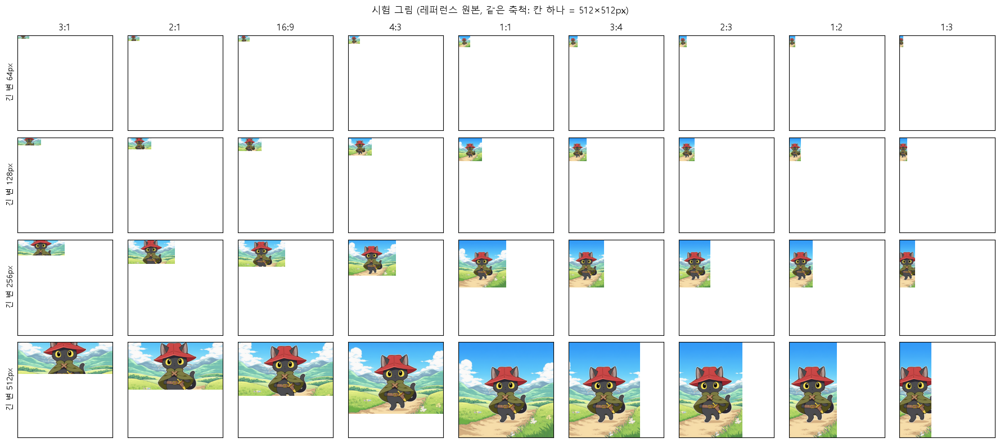

In [6]:
def make(src, ratio, size):
    rw, rh = map(int, ratio.split(':'))
    im = Image.open(src).convert('RGB')
    W0, H0 = im.size
    if W0 / H0 > rw / rh:
        cw = round(H0 * rw / rh)
        im = im.crop(((W0 - cw) // 2, 0, (W0 - cw) // 2 + cw, H0))
    else:
        ch = round(W0 * rh / rw)
        im = im.crop((0, (H0 - ch) // 2, W0, (H0 - ch) // 2 + ch))
    assert max(im.size) >= size, (src, ratio, size, im.size)  # 줄이기만 함
    w, h = (size, max(1, round(size * rh / rw))) if rw >= rh else (max(1, round(size * rw / rh)), size)
    return im.resize((w, h), Image.LANCZOS)


CASES = []
for ratio in RATIOS:
    for size in SIZES:
        case = f"r{ratio.replace(':', 'x')}__s{size}"
        c = dict(case=case, ratio=ratio, size=size)
        for k, src in SRC.items():
            p = IN_DIR / f'{k}__{case}.png'
            make(src, ratio, size).save(p)
            c[k] = str(p.resolve())
        CASES.append(c)
print('시험', len(CASES), '가지 × 칸 4 =', len(CASES) * 4, '장')

# 미리보기: 레퍼런스 원본으로 만든 시험 그림 (실제 픽셀 크기, 같은 축척)
fig, axes = plt.subplots(len(SIZES), len(RATIOS), figsize=(18, 8))
for i, size in enumerate(SIZES):
    for j, ratio in enumerate(RATIOS):
        ax = axes[i, j]
        im = Image.open(IN_DIR / f"ref__r{ratio.replace(':', 'x')}__s{size}.png")
        ax.imshow(im, extent=(0, im.width, im.height, 0))
        ax.set_xlim(0, 512); ax.set_ylim(512, 0); ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(ratio)
        if j == 0:
            ax.set_ylabel(f'긴 변 {size}px')
fig.suptitle('시험 그림 (레퍼런스 원본, 같은 축척: 칸 하나 = 512×512px)')
plt.tight_layout()
plt.show()

## 시험 실행 코드 (별도 프로세스)

Playwright 동기 API는 Jupyter 안에서 돌릴 수 없어(21·26과 같음) 별도 프로세스 파일로 저장해 실행한다.

In [7]:
CODE_RUN = r'''# 크기·비율별 시험 그림으로 상세 페이지를 그리고, 칸마다 그림이 몇 배로 커지는지(확대 배율)와 칸을 얼마나 채우는지 잰다. 노트북이 별도 프로세스로 실행하고 진행 줄을 바로 출력함
import csv
import importlib.util
import json
import sys
import time
from pathlib import Path

from PIL import Image

cfg = json.loads(Path(sys.argv[1]).read_text(encoding='utf-8'))
OUT = Path(cfg['out_dir'])
PAGES, CROPS = OUT / 'pages', OUT / 'crops'
for _d in (PAGES, CROPS):
    _d.mkdir(parents=True, exist_ok=True)
# 앱 상세 페이지 코드(src/app/core/page_html.py)를 그대로 읽어 씀 (21도 같은 코드)
_sp = importlib.util.spec_from_file_location('page_html', cfg['page_html'])
PH = importlib.util.module_from_spec(_sp)
_sp.loader.exec_module(PH)
T0 = time.perf_counter()


def log(msg):
    print(f"[{time.strftime('%H:%M:%S')} | 경과 {time.perf_counter() - T0:6.1f}초] {msg}", flush=True)


# 칸별 그림 요소의 원래 크기·화면 위치·맞춤 방식
MEASURE_JS = r"""
() => {
  const sec = t => [...document.querySelectorAll('section')].find(s => { const h = s.querySelector('h2'); return h && h.textContent === t; });
  const one = (slot, el) => { if (!el) return null; const b = el.getBoundingClientRect();
    return {slot, nw: el.naturalWidth, nh: el.naturalHeight, x: b.left + scrollX, y: b.top + scrollY, w: b.width, h: b.height,
            fit: getComputedStyle(el).objectFit}; };
  const g = sec('게임 화면'), m = sec('굿즈 디자인'), d = sec('연출 사진');
  return [one('shot', g && g.querySelector('.card img')), one('refs', g && g.querySelector('.grid img')),
          one('mockup', m && m.querySelector('.card img')), one('d', d && d.querySelector('.full img'))].filter(Boolean);
}
"""


def fit_metrics(r):
    # scale: 화면 1px당 원본 px 배율(1 넘으면 늘려서 흐려짐)
    # contain(게임 화면·굿즈·연출): fill = 그림이 칸을 채운 비율(1 미만이면 옆·위아래가 빔)
    # cover(레퍼런스 칸): shown = 원본 중 보이는 비율(1 미만이면 잘림)
    nw, nh, w, h = r['nw'], r['nh'], r['w'], r['h']
    if r['fit'] == 'cover':
        s = max(w / nw, h / nh)
        return s, 1.0, (w * h) / (nw * nh * s * s)
    s = min(w / nw, h / nh)
    return s, (nw * s) * (nh * s) / (w * h), 1.0


FIELDS = ['case', 'ratio', 'size', 'slot', 'nw', 'nh', 'box_w', 'box_h', 'fit', 'scale', 'fill', 'shown', 'need_long', 'page_h', 'sec', 'error']
CSV = OUT / 'us_results.csv'
with open(CSV, 'w', newline='', encoding='utf-8-sig') as f:
    csv.DictWriter(f, FIELDS).writeheader()

from playwright.sync_api import sync_playwright

pw = sync_playwright().start()
t = time.perf_counter()
br = pw.chromium.launch()
log(f'Chromium 시작 {time.perf_counter() - t:.2f}초')
cases = cfg['cases']
for i, c in enumerate(cases, 1):
    rows = []
    t = time.perf_counter()
    try:
        spec = dict(cfg['base'], shot=c['shot'], refs=[c['ref']], mockup=c['mockup'], d=c['d'])
        doc, _ = PH.build_html(spec)
        html_p, png_p = PAGES / f"{c['case']}.html", PAGES / f"{c['case']}.png"
        html_p.write_text(doc, encoding='utf-8')
        # 앱 render()와 같은 순서(불러오기 → 글꼴 → 글자 크기 맞춤)로 그린 뒤, 찍기 전에 칸 위치를 잼
        pg = br.new_page(viewport={'width': PH.W, 'height': 1000}, device_scale_factor=1)
        pg.goto(html_p.resolve().as_uri())
        pg.wait_for_load_state('networkidle')
        pg.evaluate('document.fonts.ready')
        pg.evaluate(PH.FIT_JS)
        boxes = pg.evaluate(MEASURE_JS)
        pg.screenshot(path=str(png_p), full_page=True)
        pg.close()
        sec = time.perf_counter() - t
        page = Image.open(png_p)
        for r in boxes:
            s, fill, shown = fit_metrics(r)
            box = tuple(round(v) for v in (r['x'], r['y'], r['x'] + r['w'], r['y'] + r['h']))
            page.crop(box).save(CROPS / f"{r['slot']}__{c['case']}.png")
            rows.append(dict(case=c['case'], ratio=c['ratio'], size=c['size'], slot=r['slot'], nw=r['nw'], nh=r['nh'], box_w=round(r['w'], 1),
                             box_h=round(r['h'], 1), fit=r['fit'], scale=round(s, 3), fill=round(fill, 3), shown=round(shown, 3),
                             need_long=round(c['size'] * s), page_h=page.height, sec=round(sec, 3)))
    except Exception as e:
        rows = [dict(case=c['case'], ratio=c['ratio'], size=c['size'], error=f'{type(e).__name__}: {e}'[:300])]
    with open(CSV, 'a', newline='', encoding='utf-8-sig') as f:
        w = csv.DictWriter(f, FIELDS)
        for r in rows:
            w.writerow({k: r.get(k, '') for k in FIELDS})
    msg = ' | '.join(f"{r['slot']} ×{r['scale']:.2f} 채움 {r['fill']:.2f} 보임 {r['shown']:.2f}" for r in rows if 'slot' in r) or rows[0]['error']
    log(f"{i:2d}/{len(cases)} {c['case']} ({time.perf_counter() - t:.2f}초) {msg}")
br.close()
pw.stop()
log('끝')
'''
(CHILD_DIR / 'run27.py').write_text(CODE_RUN, encoding='utf-8')
print('저장:', CHILD_DIR / 'run27.py', len(CODE_RUN.splitlines()), '줄')

저장: ..\outputs\upload_size\_child\run27.py 101 줄


## 실행

In [8]:
cfg = dict(out_dir=str(OUT_DIR.resolve()), page_html=str(PAGE_HTML.resolve()), base=BASE, cases=CASES, sizes=SIZES, ratios=RATIOS,
           src={k: str(p.resolve()) for k, p in SRC.items()})
(OUT_DIR / 'us_config.json').write_text(json.dumps(cfg, ensure_ascii=False, indent=1), encoding='utf-8')
t_run = time.perf_counter()
# 진행 줄을 셀 출력에 바로 보여 주고 같은 내용을 us_run.log에 남김
with open(OUT_DIR / 'us_run.log', 'w', encoding='utf-8') as log_f:
    p = subprocess.Popen([sys.executable, str(CHILD_DIR / 'run27.py'), str(OUT_DIR / 'us_config.json')], stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    for line in p.stdout:
        print(line, end='', flush=True)
        log_f.write(line)
        log_f.flush()
    p.wait()
print('종료 코드', p.returncode, '| 전체', round(time.perf_counter() - t_run, 1), '초')

[12:40:19 | 경과    3.7초] Chromium 시작 0.13초
[12:40:20 | 경과    5.4초]  1/36 r3x1__s64 (1.73초) shot ×11.09 채움 1.00 보임 1.00 | refs ×11.33 채움 1.00 보임 0.33 | mockup ×9.66 채움 1.00 보임 1.00 | d ×13.44 채움 1.00 보임 1.00
[12:40:22 | 경과    6.7초]  2/36 r3x1__s128 (1.24초) shot ×5.55 채움 1.00 보임 1.00 | refs ×5.54 채움 1.00 보임 0.34 | mockup ×4.83 채움 1.00 보임 1.00 | d ×6.72 채움 1.00 보임 1.00
[12:40:23 | 경과    7.9초]  3/36 r3x1__s256 (1.27초) shot ×2.77 채움 1.00 보임 1.00 | refs ×2.80 채움 1.00 보임 0.33 | mockup ×2.41 채움 1.00 보임 1.00 | d ×3.36 채움 1.00 보임 1.00
[12:40:24 | 경과    9.2초]  4/36 r3x1__s512 (1.30초) shot ×1.39 채움 1.00 보임 1.00 | refs ×1.39 채움 1.00 보임 0.33 | mockup ×1.21 채움 1.00 보임 1.00 | d ×1.68 채움 1.00 보임 1.00
[12:40:26 | 경과   10.5초]  5/36 r2x1__s64 (1.29초) shot ×11.09 채움 1.00 보임 1.00 | refs ×7.44 채움 1.00 보임 0.50 | mockup ×9.66 채움 1.00 보임 1.00 | d ×13.44 채움 1.00 보임 1.00
[12:40:27 | 경과   11.9초]  6/36 r2x1__s128 (1.34초) shot ×5.55 채움 1.00 보임 1.00 | refs ×3.72 채움 1.00 보임 0.50 | mockup ×4.83 채움 1.00 보임 1.00 | d ×6.72

## 결과 표

칸마다 비율(행) × 크기(열). 확대 배율이 1 이하면 늘리지 않은 것이다.

In [9]:
res = pd.read_csv(OUT_DIR / 'us_results.csv', keep_default_na=False)
err = res[res.error != '']
print('오류', len(err), '건')
if len(err):
    display(err[['case', 'error']])
res = res[res.error == ''].copy()
for c in ['size', 'nw', 'nh', 'box_w', 'box_h', 'scale', 'fill', 'shown', 'need_long', 'page_h', 'sec']:
    res[c] = pd.to_numeric(res[c])
assert len(res) == len(CASES) * 4, len(res)
print('페이지 1장 평균', round(res.drop_duplicates('case').sec.mean(), 3), '초, 페이지 높이', int(res.page_h.min()), '~', int(res.page_h.max()), 'px')
for slot, name in SLOTS.items():
    d = res[res.slot == slot]
    col = 'shown' if d.fit.iloc[0] == 'cover' else 'fill'
    print(f'\n[{name}] 맞춤 {d.fit.iloc[0]}, 칸 크기(그림 요소) 비율별:',
          {r: f'{int(g.box_w.iloc[0])}×{int(g.box_h.iloc[0])}' for r, g in d.groupby('ratio', sort=False)})
    t = d.pivot(index='ratio', columns='size', values='scale').reindex(RATIOS)
    t[col] = d.groupby('ratio').first()[col].reindex(RATIOS)
    t['need_long'] = d.groupby('ratio').need_long.max().reindex(RATIOS)
    display(t.rename(columns={s: f'확대 {s}px' for s in SIZES} | {col: ('보임' if col == 'shown' else '채움'), 'need_long': '확대 없이 긴 변(px)'}).round(3))

오류 0 건
페이지 1장 평균 1.309 초, 페이지 높이 4620 ~ 6522 px

[게임 화면 큰 칸 (A 스크린샷)] 맞춤 contain, 칸 크기(그림 요소) 비율별: {'3:1': '710×233', '2:1': '710×355', '16:9': '710×399', '4:3': '710×532', '1:1': '710×710', '3:4': '710×900', '2:3': '710×900', '1:2': '710×900', '1:3': '710×900'}


size,확대 64px,확대 128px,확대 256px,확대 512px,채움,확대 없이 긴 변(px)
ratio,,,,,,
3:1,11.094,5.547,2.773,1.387,1.000,710
2:1,11.094,5.547,2.773,1.387,1.000,710
16:9,11.094,5.547,2.773,1.387,1.000,710
4:3,11.094,5.547,2.773,1.387,1.000,710
1:1,11.094,5.547,2.773,1.387,1.000,710
3:4,14.062,7.031,3.516,1.758,0.951,900
2:3,14.062,7.031,3.516,1.758,0.852,900
1:2,14.062,7.031,3.516,1.758,0.634,900
1:3,14.062,7.031,3.516,1.758,0.416,900



[레퍼런스 칸 (레퍼런스 아트)] 맞춤 cover, 칸 크기(그림 요소) 비율별: {'3:1': '238×238', '2:1': '238×238', '16:9': '238×238', '4:3': '238×238', '1:1': '238×238', '3:4': '238×238', '2:3': '238×238', '1:2': '238×238', '1:3': '238×238'}


size,확대 64px,확대 128px,확대 256px,확대 512px,보임,확대 없이 긴 변(px)
ratio,,,,,,
3:1,11.333,5.535,2.800,1.392,0.328,725
2:1,7.438,3.719,1.859,0.930,0.500,476
16:9,6.611,3.306,1.653,0.826,0.562,423
4:3,4.958,2.479,1.240,0.620,0.750,317
1:1,3.719,1.859,0.930,0.465,1.000,238
3:4,4.958,2.479,1.240,0.620,0.750,317
2:3,5.535,2.800,1.392,0.698,0.672,358
1:2,7.438,3.719,1.859,0.930,0.500,476
1:3,11.333,5.535,2.800,1.392,0.328,725



[굿즈 디자인 칸 (F 굿즈 사진)] 맞춤 contain, 칸 크기(그림 요소) 비율별: {'3:1': '618×202', '2:1': '618×309', '16:9': '618×347', '4:3': '618×463', '1:1': '618×618', '3:4': '618×820', '2:3': '618×820', '1:2': '618×820', '1:3': '618×820'}


size,확대 64px,확대 128px,확대 256px,확대 512px,채움,확대 없이 긴 변(px)
ratio,,,,,,
3:1,9.656,4.828,2.414,1.207,1.000,618
2:1,9.656,4.828,2.414,1.207,1.000,618
16:9,9.656,4.828,2.414,1.207,1.000,618
4:3,9.656,4.828,2.414,1.207,1.000,618
1:1,9.656,4.828,2.414,1.207,1.000,618
3:4,12.812,6.406,3.203,1.602,0.995,820
2:3,12.812,6.406,3.203,1.602,0.891,820
1:2,12.812,6.406,3.203,1.602,0.663,820
1:3,12.812,6.406,3.203,1.602,0.435,820



[연출 사진 칸 (D 굿즈 사진)] 맞춤 contain, 칸 크기(그림 요소) 비율별: {'3:1': '860×282', '2:1': '860×430', '16:9': '860×483', '4:3': '860×645', '1:1': '860×860', '3:4': '860×900', '2:3': '860×900', '1:2': '860×900', '1:3': '860×900'}


size,확대 64px,확대 128px,확대 256px,확대 512px,채움,확대 없이 긴 변(px)
ratio,,,,,,
3:1,13.438,6.719,3.359,1.680,1.000,860
2:1,13.438,6.719,3.359,1.680,1.000,860
16:9,13.438,6.719,3.359,1.680,1.000,860
4:3,13.438,6.719,3.359,1.680,1.000,860
1:1,13.438,6.719,3.359,1.680,1.000,860
3:4,14.062,7.031,3.516,1.758,0.785,900
2:3,14.062,7.031,3.516,1.758,0.703,900
1:2,14.062,7.031,3.516,1.758,0.523,900
1:3,14.062,7.031,3.516,1.758,0.343,900


## 그래프: 확대 배율·채움

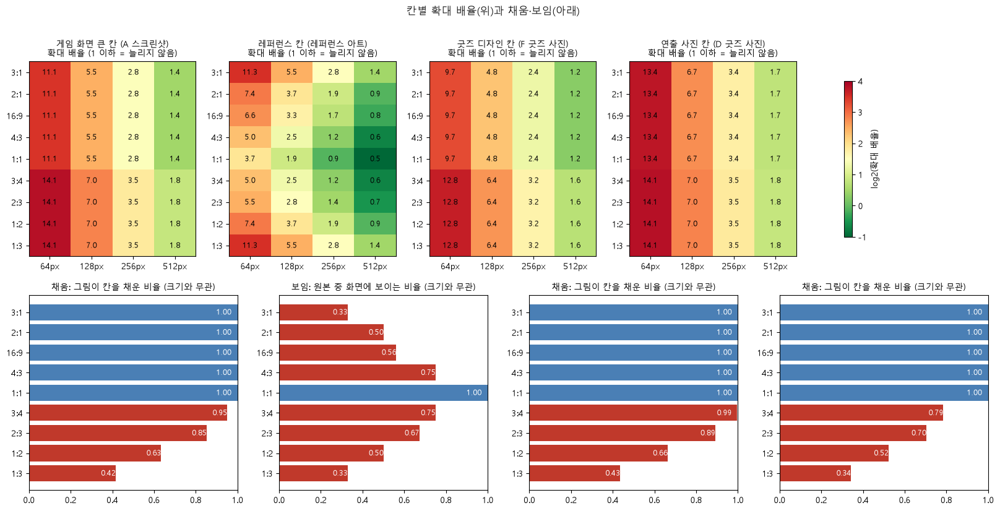

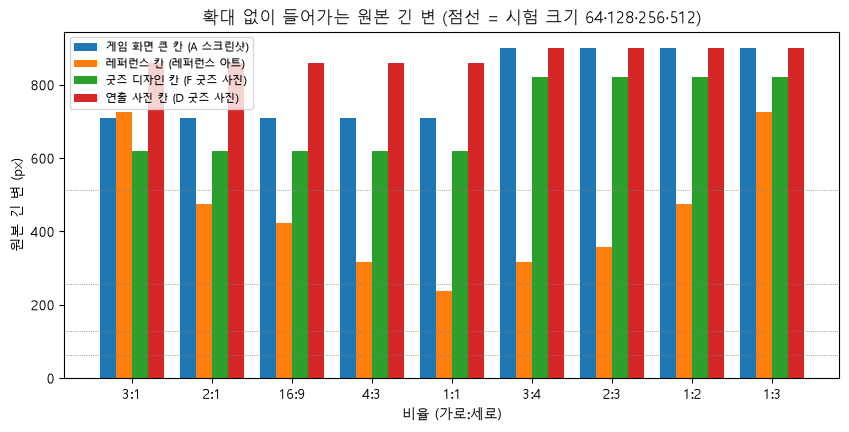

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for j, (slot, name) in enumerate(SLOTS.items()):
    d = res[res.slot == slot]
    m = d.pivot(index='ratio', columns='size', values='scale').reindex(RATIOS)
    ax = axes[0, j]
    im = ax.imshow(np.log2(m.values), cmap='RdYlGn_r', vmin=-1, vmax=4, aspect='auto')
    for (a, b), v in np.ndenumerate(m.values):
        ax.text(b, a, f'{v:.1f}', ha='center', va='center', fontsize=9, color='black')
    ax.set_xticks(range(len(SIZES)), [f'{s}px' for s in SIZES]); ax.set_yticks(range(len(RATIOS)), RATIOS)
    ax.set_title(f'{name}\n확대 배율 (1 이하 = 늘리지 않음)', fontsize=10)
    col = 'shown' if d.fit.iloc[0] == 'cover' else 'fill'
    v = d.groupby('ratio').first()[col].reindex(RATIOS)
    ax = axes[1, j]
    ax.barh(range(len(RATIOS)), v.values, color=['#4a7fb5' if x >= .999 else '#c0392b' for x in v.values])
    for k, x in enumerate(v.values):
        ax.text(min(x, .97), k, f'{x:.2f}', va='center', ha='right', color='white', fontsize=9)
    ax.set_yticks(range(len(RATIOS)), RATIOS); ax.invert_yaxis(); ax.set_xlim(0, 1)
    ax.set_title(('보임: 원본 중 화면에 보이는 비율' if col == 'shown' else '채움: 그림이 칸을 채운 비율') + ' (크기와 무관)', fontsize=10)
fig.colorbar(im, ax=axes[0, :], shrink=.8, label='log2(확대 배율)')
fig.suptitle('칸별 확대 배율(위)과 채움·보임(아래)')
fig.savefig(OUT_DIR / 'us_summary.png', dpi=110, bbox_inches='tight')
plt.show()

# 확대 없이 들어가는 원본 긴 변 (칸·비율별)
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(RATIOS))
for k, (slot, name) in enumerate(SLOTS.items()):
    v = res[res.slot == slot].groupby('ratio').need_long.max().reindex(RATIOS)
    ax.bar(x + (k - 1.5) * .2, v.values, .2, label=name)
for s in SIZES:
    ax.axhline(s, color='gray', lw=.6, ls=':')
ax.set_xticks(x, RATIOS); ax.set_ylabel('원본 긴 변 (px)'); ax.set_xlabel('비율 (가로:세로)')
ax.set_title('확대 없이 들어가는 원본 긴 변 (점선 = 시험 크기 64·128·256·512)'); ax.legend(fontsize=8)
fig.savefig(OUT_DIR / 'us_need_long.png', dpi=110, bbox_inches='tight')
plt.show()

## 칸별 모양 (비율 × 크기)

페이지에서 칸 부분만 잘라 같은 축척으로 줄여 보인다. 비율에 따른 빈 공간(좁은 띠)과 잘림을 본다.

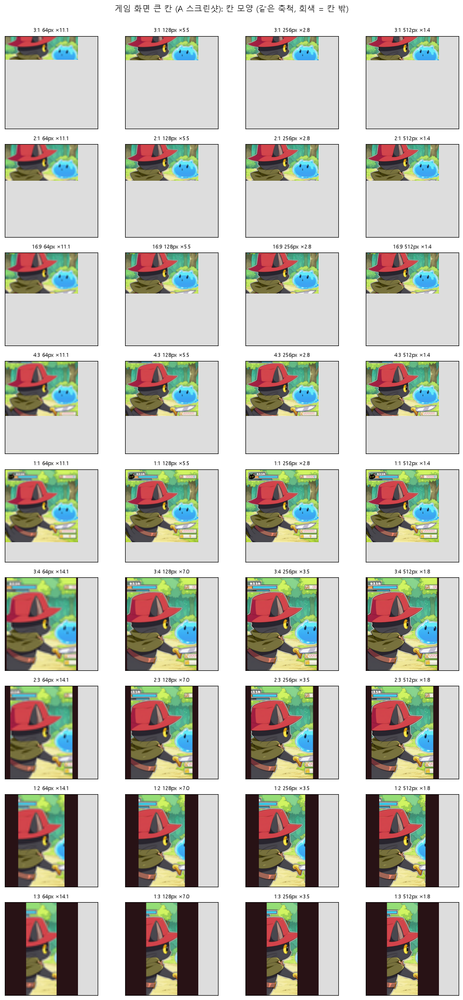

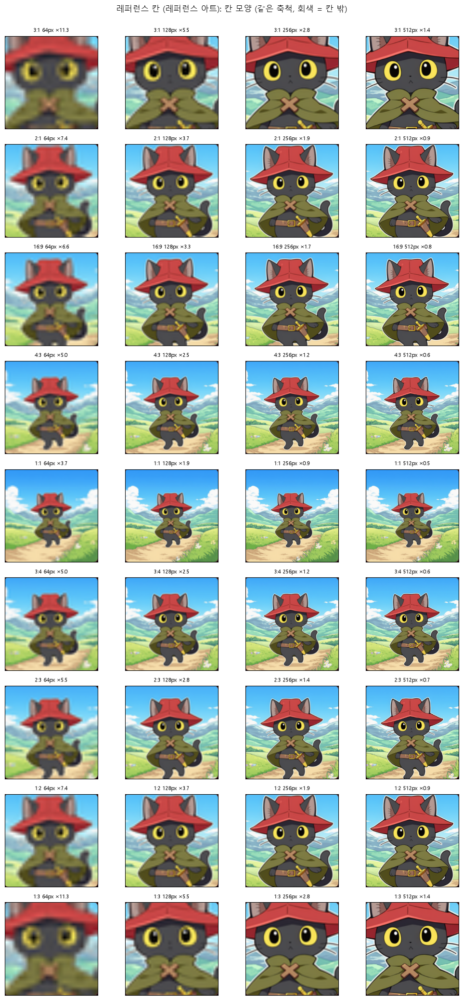

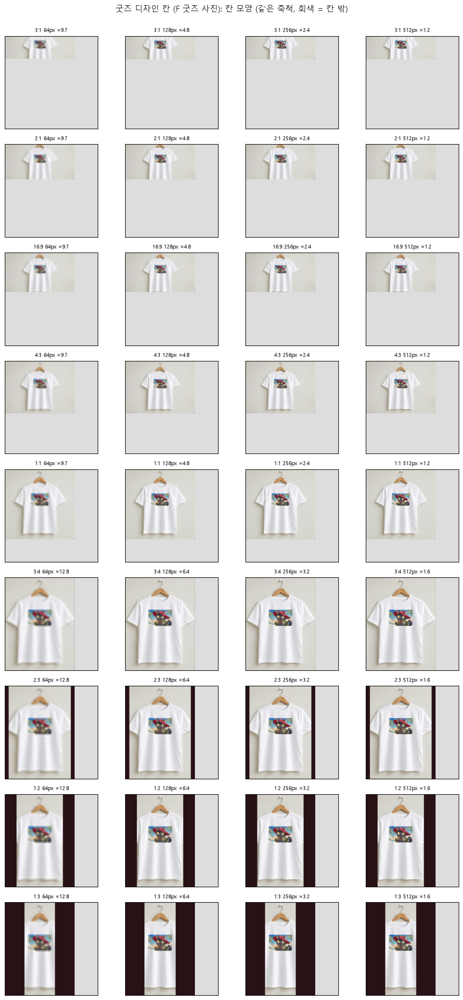

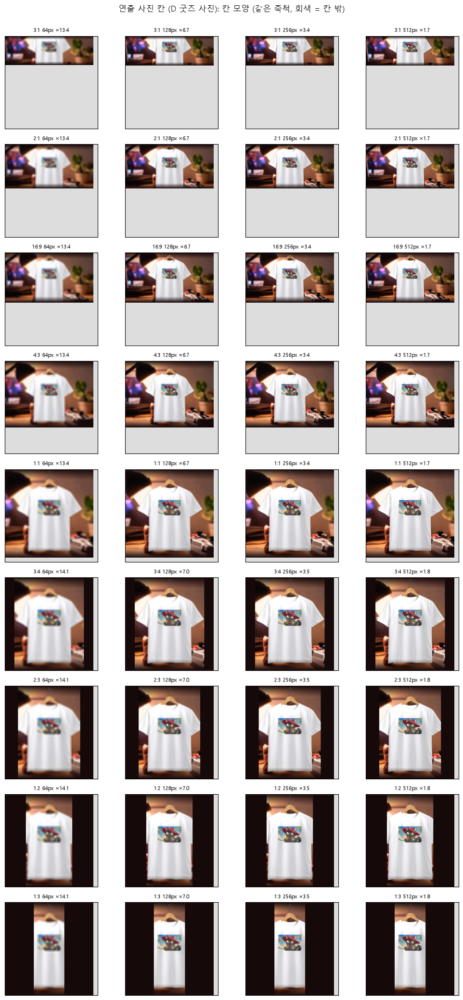

In [11]:
CELL = 200
for slot, name in SLOTS.items():
    fig, axes = plt.subplots(len(RATIOS), len(SIZES), figsize=(len(SIZES) * 2.6, len(RATIOS) * 2.3))
    mx = max(Image.open(OUT_DIR / 'crops' / f'{slot}__{c["case"]}.png').size[k] for c in CASES for k in (0, 1))
    for i, ratio in enumerate(RATIOS):
        for j, size in enumerate(SIZES):
            ax = axes[i, j]
            im = Image.open(OUT_DIR / 'crops' / f"{slot}__r{ratio.replace(':', 'x')}__s{size}.png")
            ax.imshow(im, extent=(0, im.width, im.height, 0))
            ax.set_xlim(0, mx); ax.set_ylim(mx, 0); ax.set_xticks([]); ax.set_yticks([])
            ax.set_facecolor('#dddddd')
            r = res[(res.slot == slot) & (res.ratio == ratio) & (res['size'] == size)].iloc[0]
            ax.set_title(f'{ratio} {size}px ×{r.scale:.1f}', fontsize=8)
    fig.suptitle(f'{name}: 칸 모양 (같은 축척, 회색 = 칸 밖)', y=1.0)
    plt.tight_layout()
    fig.savefig(OUT_DIR / f'us_layout_{slot}.png', dpi=90, bbox_inches='tight')
    plt.show()

## 흐림 확대 비교 (실제 픽셀)

칸마다 1:1·16:9 그림의 가운데 240×240px를 페이지 PNG 그대로(줄이거나 키우지 않음) 잘라 크기별로 놓는다.

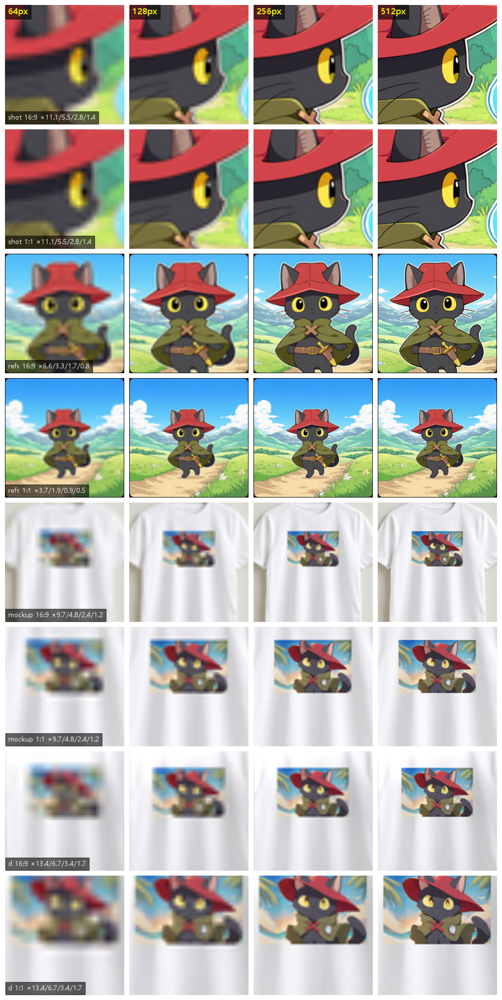

In [12]:
Z = 240
rows = [(slot, ratio) for slot in SLOTS for ratio in ['16:9', '1:1']]
sheet = Image.new('RGB', (Z * len(SIZES) + 10 * (len(SIZES) - 1), Z * len(rows) + 10 * (len(rows) - 1)), (255, 255, 255))
for i, (slot, ratio) in enumerate(rows):
    for j, size in enumerate(SIZES):
        im = Image.open(OUT_DIR / 'crops' / f"{slot}__r{ratio.replace(':', 'x')}__s{size}.png").convert('RGB')
        cx, cy = im.width // 2, im.height // 2
        tile = im.crop((cx - Z // 2, cy - Z // 2, cx + Z // 2, cy + Z // 2))
        sheet.paste(tile, (j * (Z + 10), i * (Z + 10)))
fig = plt.figure(figsize=(sheet.width / 100, sheet.height / 100), dpi=100)
ax = fig.add_axes([0, 0, 1, 1]); ax.imshow(sheet); ax.axis('off')
for j, size in enumerate(SIZES):
    ax.text(j * (Z + 10) + 6, 18, f'{size}px', color='yellow', fontsize=12, weight='bold', bbox=dict(fc='black', alpha=.6))
for i, (slot, ratio) in enumerate(rows):
    r = res[(res.slot == slot) & (res.ratio == ratio)].set_index('size').scale
    ax.text(6, i * (Z + 10) + Z - 10, f'{slot} {ratio} ×' + '/'.join(f'{r[s]:.1f}' for s in SIZES), color='white', fontsize=10,
            bbox=dict(fc='black', alpha=.6))
# 줄이거나 키우지 않도록 그림 1px = 저장 1px (dpi 100, 그림 크기 = 시트 크기)
fig.savefig(OUT_DIR / 'us_zoom.png', dpi=100)
plt.show()

## 기준 고르기

이 노트북은 기준을 정하지 않는다. 아래 표와 위 그림을 보고 올리는 그림 종류마다 두 가지를 정한다.

- 최소 크기: "확대 없이 들어가는 원본 긴 변" 표와 흐림 확대 비교 그림을 보고, 어느 확대 배율까지 받아들일지 정한다.
- 허용 비율: 채움·보임 그래프와 칸 모양 그림을 보고, 어느 비율까지 받아들일지 정한다.
- 정해진 기준은 앱에서 올릴 때 검사하고, 기준 밖이면 막고 필요한 크기·비율을 안내한다(11/04 결정).

In [13]:
# 올리는 그림 종류별 칸 (A 스크린샷 → 게임 화면 큰 칸, 레퍼런스 아트 → 레퍼런스 칸, 굿즈 사진 → 굿즈 디자인·연출 사진 칸)
view = []
for slot, name in SLOTS.items():
    d = res[res.slot == slot].groupby('ratio', sort=False).agg(need_long=('need_long', 'max'), fill=('fill', 'first'), shown=('shown', 'first'))
    for ratio, r in d.reindex(RATIOS).iterrows():
        view.append(dict(칸=name, 비율=ratio, 확대없이_긴변=int(r.need_long), 채움=r.fill, 보임=r.shown,
                         **{f'{s}px 확대': res[(res.slot == slot) & (res.ratio == ratio) & (res['size'] == s)].scale.iloc[0] for s in SIZES}))
view = pd.DataFrame(view)
view.to_csv(OUT_DIR / 'us_view.csv', index=False, encoding='utf-8-sig')
pd.set_option('display.max_rows', 60)
display(view.round(3))

,칸,비율,확대없이_긴변,채움,보임,64px 확대,128px 확대,256px 확대,512px 확대
0,게임 화면 큰 칸 (A 스크린샷),3:1,710,1.000,1.000,11.094,5.547,2.773,1.387
1,게임 화면 큰 칸 (A 스크린샷),2:1,710,1.000,1.000,11.094,5.547,2.773,1.387
2,게임 화면 큰 칸 (A 스크린샷),16:9,710,1.000,1.000,11.094,5.547,2.773,1.387
3,게임 화면 큰 칸 (A 스크린샷),4:3,710,1.000,1.000,11.094,5.547,2.773,1.387
4,게임 화면 큰 칸 (A 스크린샷),1:1,710,1.000,1.000,11.094,5.547,2.773,1.387
5,게임 화면 큰 칸 (A 스크린샷),3:4,900,0.951,1.000,14.062,7.031,3.516,1.758
6,게임 화면 큰 칸 (A 스크린샷),2:3,900,0.852,1.000,14.062,7.031,3.516,1.758
7,게임 화면 큰 칸 (A 스크린샷),1:2,900,0.634,1.000,14.062,7.031,3.516,1.758
8,게임 화면 큰 칸 (A 스크린샷),1:3,900,0.416,1.000,14.062,7.031,3.516,1.758
9,레퍼런스 칸 (레퍼런스 아트),3:1,725,1.000,0.328,11.333,5.535,2.800,1.392
